# R1 · Nombres et calcul — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r1_nombres_calcul/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R1.1 à R1.14, R1.17 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R1.21 | PGCD par l'algorithme d'Euclide et fraction irréductible · `gcd`, `simplify_fraction` | 🔨 | ★★ | 40 |
|  | R1.22 | Additionner deux fractions sans passer par les décimaux · `add_fractions` | 🔨 | ★★ | 30 |
|  | R1.25 | Calculer exactement avec `fractions.Fraction` | 📦 | ★ | 10 |
|  | R1.28 | Chasse à l'erreur : cinq calculs de fractions et de puissances | 🐛 | ★ | 15 |
|  | R1.29 | Chasse à l'erreur : `-3**2` et les parenthèses | 🐛 | ★ | 10 |
| B | R1.23 | La notation scientifique à n chiffres significatifs · `scientific_notation` | 🔨 | ★★ | 40 |
|  | R1.26 | Prédire : arrondir deux fois, est-ce arrondir une fois ? | 🔮 | ★ | 10 |
|  | R1.30 | Les ordres de grandeur sur une échelle : de l'atome aux paramètres d'un LLM | 🎨 | ★ | 15 |
| C | R1.24 | Évolutions successives et moyenne pondérée · `successive_changes`, `weighted_mean` | 🔨 | ★ | 30 |
|  | R1.27 | Après n hausses de 10 % : tracer et comparer à une hausse de 10n % | 🔬 | ★★ | 20 |
|  | R1.31 | Écrire la docstring d'une fonction (format NumPy) | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : priorités, fractions, puissances, racines, notation scientifique, pourcentages, moyennes.
- Écrire les six fonctions de `mymath/arith.py` et les tester.
- Calculer exactement avec `Fraction`, repérer les erreurs de calcul classiques, voir une hausse répétée s'envoler.

**Rappel express.** $\frac{a}{b} + \frac{c}{d} = \frac{ad + cb}{bd}$ ; diviser, c'est multiplier par l'inverse ; $a^{-n} = \frac{1}{a^n}$ ; $\sqrt{ab} = \sqrt{a}\sqrt{b}$ ; une évolution de $t$ multiplie par $1 + t$, et les coefficients successifs se multiplient.

## Partie 0 · Vérifier tes exercices papier (✏️ R1.1 à R1.14, 🔗 R1.17)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire (une fraction entre guillemets, `"11/20"` ; un décimal avec un point, `0.75` ; une liste, `[3.5, -2]` ; un texte entre guillemets, `"XYZ"`), jamais le calcul lui-même. Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex R1.1 — Placer des nombres sur la droite numérique et les ranger**

In [3]:
wbm.record("R1.1a", "ACEDBF", mistakes={"compare 0,6 et 2/3 : écris 2/3 en décimal, avec trois chiffres après la virgule": "ACEBDF", "parmi les négatifs, le plus petit est le plus loin de zéro": "ECADBF", "l'ordre croissant va du plus petit au plus grand": "FBDECA"})
wbm.record("R1.1b", len([k for k in range(-5, 5) if -2.5 < k < 1.75]), mistakes={"n'oublie pas 0, qui est un entier relatif": 3, "un entier plus petit que A n'est pas entre A et F": 5})
wbm.record("R1.1c", "C", mistakes={"E vaut −1,5 : ce n'est pas un entier": "CE"})
wbm.record("R1.1d", "B", mistakes={"F vaut 1,75 : son écriture décimale s'arrête, c'est un décimal": "BF", "C vaut −2 : un entier est aussi un décimal": "BC"})

WBM_ANSWER {"hash": "8d7aac34836bd988d5dd2c5ae665191ef940dc03d7d4506b6eccdf922025ad30", "id": "R1.1a", "kind": "str", "mistakes": {"23b8bbd5566d9533223e2420fbb61f14a72271dc487b439606cf2711d5f11f63": "compare 0,6 et 2/3 : écris 2/3 en décimal, avec trois chiffres après la virgule", "4e4c1cb347e91c1424d45e7fafed4ab3e74f046d78cb2a3954205aea3cf41c47": "parmi les négatifs, le plus petit est le plus loin de zéro", "b5e6e9211e25e8f5c0aa7f3f5177656a6ae4aa2351b6e321a2b36e145cc1e16d": "l'ordre croissant va du plus petit au plus grand"}}
📝 Ex R1.1a : réponse enregistrée (str).
WBM_ANSWER {"hash": "c1b705b7eb778bdf6f50bd55eb869e5c552907b257da0ce60fcff311c3045e27", "id": "R1.1b", "kind": "int", "magnitude": 0, "mistakes": {"5d6e040e29f5dcb60ae697a8089446a2c0cfe92b8c103d266fef373fb09966ac": "un entier plus petit que A n'est pas entre A et F", "e35a7e99290ea574e72f103fef08ca709ffb9447d82f8bb1cc6ea2d4477343f2": "n'oublie pas 0, qui est un entier relatif"}, "sign": 1}
📝 Ex R1.1b : réponse enregistrée (

**Ex R1.2 — Calculer avec les priorités et les signes**

In [4]:
wbm.record("R1.2a", 18 - 4 * 3 + 2, mistakes={"+ et − se font de gauche à droite : la soustraction d'abord, puis l'addition": 4, "la multiplication passe avant la soustraction": 44})
wbm.record("R1.2b", -6 - (-9), mistakes={"soustraire un négatif, c'est ajouter": -15})
wbm.record("R1.2c", (-2) ** 3, mistakes={"trois facteurs négatifs : le produit est négatif": 8, "une puissance est un produit de facteurs égaux, pas une multiplication par l'exposant": -6})
wbm.record("R1.2d", -2 ** 4, mistakes={"la puissance passe avant le signe moins : seul 2 est élevé à la puissance": 16})
wbm.record("R1.2e", 20 // 4 * 5, mistakes={"× et ÷ ont la même priorité : on calcule de gauche à droite": 1})
wbm.record("R1.2f", 3 - 2 * (4 - 7) ** 2, mistakes={"la multiplication passe avant la soustraction": 9, "le carré d'un nombre négatif est positif": 21})
wbm.record("R1.2g", (-12) // (-3) - 5, mistakes={"moins divisé par moins donne plus": -9})
wbm.record("R1.2h", -(5 - 11) + 2 * (-4), mistakes={"un signe moins devant une parenthèse change le signe de chaque terme": -14, "deux fois un nombre négatif donne un nombre négatif": 14})

WBM_ANSWER {"hash": "d7d766238e5604465ad1c074f84580d97016d74f68216f8f7007fa66e7b8fc75", "id": "R1.2a", "kind": "int", "magnitude": 0, "mistakes": {"3ea0fe1f408e5514c1bf580892b840481c07e4d0414dc73c65f2fdfac60ea818": "la multiplication passe avant la soustraction", "4bd704199386f5efc55e57ddfef8b73d0297c75372637dc4b930122ff42fcd8f": "+ et − se font de gauche à droite : la soustraction d'abord, puis l'addition"}, "sign": 1}
📝 Ex R1.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "83862b5e91a6c49b3892cce6d17112b17722180c1c68a18a92d79fe58981b465", "id": "R1.2b", "kind": "int", "magnitude": 0, "mistakes": {"bb12f41be9fb91ebda4ab35a2c6ef71b18ae909fada24f94199d38f001fab8ba": "soustraire un négatif, c'est ajouter"}, "sign": 1}
📝 Ex R1.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "7a3e3480b0622ecb790502ee794db9838b19bdb7a7791a530e40c758119cdbea", "id": "R1.2c", "kind": "int", "magnitude": 0, "mistakes": {"83d5247dc4c58fad6db8a13e16282655a8a57f74034b16cddcf5ec903ca81ef8": "trois facteur

**Ex R1.3 — Calcul mental avec la distributivité : 17 × 99, 23 × 101**

In [5]:
wbm.record("R1.3a", 17 * 99, mistakes={"99 = 100 − 1 : retire le second produit, 17 × 1": 1700})
wbm.record("R1.3b", 23 * 101, mistakes={"101 = 100 + 1 : ajoute le second produit, 23 × 1": 2300})
wbm.record("R1.3c", 9 * 34 + 9 * 66, mistakes={"factorise par 9 : 9 × (34 + 66)": 990})
wbm.record("R1.3d", 25 * 44)
wbm.record("R1.3e", 8 * 47 - 8 * 7, mistakes={"factorise par 8 : 8 × (47 − 7)": 432})

WBM_ANSWER {"hash": "be86193e445bcc8af113cb9302d83f2f552ef1e09aa81ba03b8a01c82da42246", "id": "R1.3a", "kind": "int", "magnitude": 3, "mistakes": {"afaa582892936818b8dcaa517b14d44e2e9ddb2eab4d0b30611209419f8da4d6": "99 = 100 − 1 : retire le second produit, 17 × 1"}, "sign": 1}
📝 Ex R1.3a : réponse enregistrée (int).
WBM_ANSWER {"hash": "1fe09c9f92e42da7dc7413125abf3e9389828abe7a45607194589a673946c1e0", "id": "R1.3b", "kind": "int", "magnitude": 3, "mistakes": {"b77f133bfb7551b32fb75cfc08ea6b13e3993a5bc1a6ba9b028d3782d2fc3e5c": "101 = 100 + 1 : ajoute le second produit, 23 × 1"}, "sign": 1}
📝 Ex R1.3b : réponse enregistrée (int).
WBM_ANSWER {"hash": "24495cf4c0188b6023b567cef688023bd9d8d6d7891406ea25ba5e84423dd7ee", "id": "R1.3c", "kind": "int", "magnitude": 2, "mistakes": {"750bee90b3c8ec65a0ba1fac287aebe1c357483e060f19b965e422e97e6a1317": "factorise par 9 : 9 × (34 + 66)"}, "sign": 1}
📝 Ex R1.3c : réponse enregistrée (int).
WBM_ANSWER {"hash": "66c29b8254c26bd22c786b812cc3505cb9d9de40

**Ex R1.4 — Simplifier des fractions avec le PGCD**

In [6]:
wbm.record("R1.4a", math.gcd(45, 75), mistakes={"5 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun": 5, "3 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun": 3})
wbm.record("R1.4b", Fraction(45, 75), kind="fraction", simplified=True)
wbm.record("R1.4c", math.gcd(252, 198), mistakes={"le PGCD est le dernier reste non nul : continue jusqu'au reste 0": 36, "6 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun": 6})
wbm.record("R1.4d", Fraction(252, 198), kind="fraction", simplified=True)
wbm.record("R1.4e", Fraction(-56, 98), kind="fraction", simplified=True)
wbm.record("R1.4f", Fraction(1001, 1309), kind="fraction", simplified=True)

WBM_ANSWER {"hash": "389baf00c7e19a3873aefb78e87ef7cac3e11673b76a6e6f0389b39e4b90a886", "id": "R1.4a", "kind": "int", "magnitude": 1, "mistakes": {"dbacdd1c75900ff993c54689634e790b8b9290d72a10611d2be2ac37de29ab3b": "5 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun", "f5e6a070fb7ecb79682be2c121ec5c725fd1ef8b3f1328c2c2dca1d53251c234": "3 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun"}, "sign": 1}
📝 Ex R1.4a : réponse enregistrée (int).


WBM_ANSWER {"hash": "2df9acdc3f4c0e7c8a853f6b371d0817203054c1ac3106fa26c1590d86a4d15d", "id": "R1.4b", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex R1.4b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "516c53709770363a274e4447f2d0af249586c22f9b241fe8d4c1e5239fe298fe", "id": "R1.4c", "kind": "int", "magnitude": 1, "mistakes": {"03b944bf0aca4c0b26ca16f12a78f0adae8f186f0e581cd25eb3ac278bfc1013": "le PGCD est le dernier reste non nul : continue jusqu'au reste 0", "89e4f10fc5d9a6a2fd5bae1e4d86c901f90ac81bedfac1134beb781c3ddf27a7": "6 divise les deux nombres, mais ce n'est pas le plus grand diviseur commun"}, "sign": 1}
📝 Ex R1.4c : réponse enregistrée (int).
WBM_ANSWER {"hash": "d31537e9ca229057333b0417a63d2ba30be645d58bfb8af73f01f441834df5b3", "id": "R1.4d", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex R1.4d : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "7ca5c1a6380e03745b03ac6fc0709d0ddf91ce1135f5b34df9d1ea83743cb477", "id": "R1.4e", "kind": "fraction"

**Ex R1.5 — Additionner, multiplier et diviser des fractions**

In [7]:
wbm.record("R1.5a", Fraction(3, 10) + Fraction(4, 15), kind="fraction", simplified=True, mistakes={"on n'additionne ni les numérateurs ni les dénominateurs entre eux : mets au même dénominateur": "7/25"})
wbm.record("R1.5b", Fraction(7, 12) - Fraction(5, 8), kind="fraction", simplified=True, mistakes={"on ne soustrait pas les dénominateurs : mets au même dénominateur": "1/2"})
wbm.record("R1.5c", Fraction(14, 15) * Fraction(25, 21), kind="fraction", simplified=True)
wbm.record("R1.5d", Fraction(7, 9) / Fraction(14, 27), kind="fraction", simplified=True, mistakes={"diviser par une fraction, c'est multiplier par son inverse": "98/243"})
wbm.record("R1.5e", 1 + 1 / (1 + Fraction(1, 2)), kind="fraction", simplified=True, mistakes={"1 divisé par une fraction, c'est l'inverse de cette fraction": "5/2"})
wbm.record("R1.5f", Fraction(3, 8) * 240, mistakes={"prendre une fraction d'une quantité, c'est multiplier par cette fraction": 640})

WBM_ANSWER {"hash": "99ee1d255dbfc4d4da3ce72c9507eff499a6a2801499965bdda331837f4bc778", "id": "R1.5a", "kind": "fraction", "mistakes": {"b696bda0bc67d4961faaaf555366dba676d6c518e5bee5b292d3f3e6b8507272": "on n'additionne ni les numérateurs ni les dénominateurs entre eux : mets au même dénominateur"}, "sign": 1, "simplified": true}
📝 Ex R1.5a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "966753c9ba605ee0e140edee5519722d4abfca83bc1ab8f71b75c816747cc54a", "id": "R1.5b", "kind": "fraction", "mistakes": {"24d21a8c2d7b5d0c814800f72dbb8e1ec3325cffd46b734b6992bbf27d79d4c8": "on ne soustrait pas les dénominateurs : mets au même dénominateur"}, "sign": -1, "simplified": true}
📝 Ex R1.5b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "271be378e2c46dee81ac012de3d5cb2f6342e44f306d14f5f623c6fd3e7c7159", "id": "R1.5c", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex R1.5c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "d035d11ac1770a7f0d40c60973cf118ee19fbcab7d5641a8800

**Ex R1.6 — Comparer des fractions**

In [8]:
wbm.record("R1.6a", max(Fraction(7, 9), Fraction(11, 14)), kind="fraction", mistakes={"compare les produits en croix : 7 × 14 et 11 × 9": "7/9"})
wbm.record("R1.6b", "RQP", mistakes={"l'ordre croissant va du plus petit au plus grand": "PQR", "compare Q et R avec le dénominateur commun 24": "QRP"})
wbm.record("R1.6c", Fraction(5, 12), kind="fraction", mistakes={"4/12 vaut exactement 1/3 : « strictement » l'exclut": "1/3", "6/12 vaut exactement 1/2 : « strictement » l'exclut": "1/2"})
wbm.record("R1.6d", Fraction(13, 40) > Fraction(1, 3), mistakes={"compare les produits en croix : 13 × 3 et 40 × 1": True})

WBM_ANSWER {"hash": "d988e42562e6757c78e865c5b610a80f0b6c850bc53849a4ea976ebff7ea282b", "id": "R1.6a", "kind": "fraction", "mistakes": {"9742c1cbff689de61fce358f422f54d3fc9ab05fdf5be4ce1fcdb0c53a86bcab": "compare les produits en croix : 7 × 14 et 11 × 9"}, "sign": 1}
📝 Ex R1.6a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "bb8ba9549161219f759420d6177b1674c5942dd22ba698c649fe7b7fb9fe27d5", "id": "R1.6b", "kind": "str", "mistakes": {"777151eb013f89c557551aaef71d8232b3cea6651c00e72cda5051f910d1082b": "compare Q et R avec le dénominateur commun 24", "c626c7645ccc7714cb0349c1e5d68b3e53ab5a6a6bafc77aeb821673128446b8": "l'ordre croissant va du plus petit au plus grand"}}
📝 Ex R1.6b : réponse enregistrée (str).
WBM_ANSWER {"hash": "799afc852b153dff4e75b4cef3e3e750a0739dca55b7783b9ed4af7398bb4b0a", "id": "R1.6c", "kind": "fraction", "mistakes": {"324226a0fbcdae73d642c97fba192fab16f2e28a6838ecc1b62d54c74180e67e": "6/12 vaut exactement 1/2 : « strictement » l'exclut", "66b920edabe0979471

**Ex R1.7 — Appliquer les règles des puissances**

In [9]:
wbm.record("R1.7a", 7 ** (5 - 2 - 2), mistakes={"additionne les exposants avec leur signe : l'exposant −2 compte en moins": 16807})
wbm.record("R1.7b", 2 ** (3 * 2 - 4), mistakes={"(a^m)^n = a^(m × n) : on multiplie les exposants": 2})
wbm.record("R1.7c", Fraction(5 ** 3, 5 ** 4), kind="fraction", mistakes={"5 tout seul, c'est 5 puissance 1 : compte-le au numérateur": "1/25"})
wbm.record("R1.7d", 4 ** 3 * 25 ** 3, mistakes={"(ab)^n = a^n × b^n : on multiplie les bases, l'exposant reste le même": 10 ** 12})
wbm.record("R1.7e", Fraction(3, 2) ** 3, kind="fraction", mistakes={"la puissance porte sur le numérateur ET sur le dénominateur": "27/2"})
wbm.record("R1.7f", (-1) ** 2027, mistakes={"l'exposant est impair : un nombre impair de facteurs −1": 1})

WBM_ANSWER {"hash": "edfc7a078c6467ac9ccfe64b22b1cd33666833e7aa7db4f6f13de9a829dc4f27", "id": "R1.7a", "kind": "int", "magnitude": 0, "mistakes": {"a10a69cf0d49ec25286b5a040896a59d056acf8357d64c11817af00c01204c1e": "additionne les exposants avec leur signe : l'exposant −2 compte en moins"}, "sign": 1}
📝 Ex R1.7a : réponse enregistrée (int).
WBM_ANSWER {"hash": "118b68a8a53e83e06027da0b7f0b735cbc0d7a85cb49c47a43bc148ec2fb1ae8", "id": "R1.7b", "kind": "int", "magnitude": 0, "mistakes": {"417245caefdadca973aa5e71723e219daf4d83f23092e513ae00654b415d0b26": "(a^m)^n = a^(m × n) : on multiplie les exposants"}, "sign": 1}
📝 Ex R1.7b : réponse enregistrée (int).
WBM_ANSWER {"hash": "35c4afba66615c2376377a907f9b1d50bf13762fe1a88a06caa035bbc23281e2", "id": "R1.7c", "kind": "fraction", "mistakes": {"df66928c13f450c190ba022e18e664f91df28dd6b3b756a53ffb631cb95d2b51": "5 tout seul, c'est 5 puissance 1 : compte-le au numérateur"}, "sign": 1}
📝 Ex R1.7c : réponse enregistrée (fraction).
WBM_ANSWER {"ha

**Ex R1.8 — Puissances négatives et puissances de 10**

In [10]:
wbm.record("R1.8a", Fraction(1, 4 ** 2), kind="fraction", mistakes={"un exposant négatif donne un inverse, pas un nombre négatif": "-16", "4 puissance −2, c'est 1 sur 4 au carré, pas 1 sur 4 fois 2": "1/8"})
wbm.record("R1.8b", Fraction(1, 3) ** -2, kind="fraction", mistakes={"un exposant négatif retourne la fraction": "1/9"})
wbm.record("R1.8c", Fraction(1, 10 ** 5), kind="fraction", mistakes={"10^a × 10^b = 10^(a+b) : on additionne les exposants, on ne les multiplie pas": "1/1000000"})
wbm.record("R1.8d", [4, -6], decimals=3, mistakes={"le carré porte aussi sur la mantisse 2": [2, -6], "(10^a)² = 10^(2a) : l'exposant est multiplié par 2": [4, -5]})
wbm.record("R1.8e", 9 - (-3), mistakes={"diviser par 10^(−3), c'est soustraire −3 à l'exposant, donc ajouter 3": 6, "on demande l'exposant k, pas la puissance de 10 elle-même": 10 ** 12})
wbm.record("R1.8f", int(0.5 ** -3), mistakes={"un exposant négatif donne un inverse, pas un nombre négatif": -8})
wbm.record("R1.8g", -3 - (-9), mistakes={"une nanoseconde est bien plus petite qu'une milliseconde : il y en a beaucoup dedans": -6, "une milliseconde vaut 10^(−3) s et une nanoseconde 10^(−9) s : divise l'une par l'autre": 3, "on demande l'exposant k, pas la puissance de 10 elle-même": 10 ** 6})

WBM_ANSWER {"hash": "9e467e09fac8d65a80d63f6a99f671a7671fd5bd5dc98dc55f2596f931ac208a", "id": "R1.8a", "kind": "fraction", "mistakes": {"a936acdfcb6bf66a2a4028875fc729a02a9f04f5782be90ebf2767a7922b543e": "un exposant négatif donne un inverse, pas un nombre négatif", "abf9559284c241dee577e5a7dae46877e9b77f8e29364143b517dbfdc5dcaa29": "4 puissance −2, c'est 1 sur 4 au carré, pas 1 sur 4 fois 2"}, "sign": 1}
📝 Ex R1.8a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "49d85121dba9c5f76ff16defcdd24c7198c5947dd54d199c68dd64ef6c79add0", "id": "R1.8b", "kind": "fraction", "mistakes": {"af62dd732b1ddc33dafdada9f033fb4763d8a0f5958c97782c6bc1bfaa6346d2": "un exposant négatif retourne la fraction"}, "sign": 1}
📝 Ex R1.8b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "fd79cec5524ec8c6b35322444f3ea205f4d3dc826a7d1a3a2254ed27fcabb2f1", "id": "R1.8c", "kind": "fraction", "mistakes": {"d0c60c405ebd933708fe00e27a1f5f29aa8d1a288bdeb71002d17354bfb157fe": "10^a × 10^b = 10^(a+b) : on addition

**Ex R1.9 — Simplifier des racines carrées**

In [11]:
wbm.record("R1.9a", 10, mistakes={"tu as gardé le carré parfait : c'est sa racine carrée qui sort devant la racine": 100})
wbm.record("R1.9b", 5, mistakes={"tu as gardé le carré parfait : c'est sa racine carrée qui sort devant la racine": 25})
wbm.record("R1.9c", math.isqrt(12 * 3), mistakes={"le produit des racines est la racine du produit : il reste à prendre cette racine": 36})
wbm.record("R1.9d", math.isqrt(98 // 2), mistakes={"le quotient des racines est la racine du quotient : il reste à prendre cette racine": 49})
wbm.record("R1.9e", Fraction(7, 10), kind="fraction", mistakes={"élève ta réponse au carré pour vérifier : elle doit redonner 0,49": "7/100"})
wbm.record("R1.9f", 3 * 2 - 3, mistakes={"√20 = 2√5 : n'oublie pas de le multiplier par 3": -1})
wbm.record("R1.9g", math.isqrt((-9) ** 2), mistakes={"une racine carrée n'est jamais négative": -9})

WBM_ANSWER {"hash": "3fa1ac934292ff728dc1e0dd857c00483392912d01ca46864bc49fa4670b6879", "id": "R1.9a", "kind": "int", "magnitude": 1, "mistakes": {"6c1a0d7587d0304b3498ad7dea3039e0421bb055de46b66494549685d058cc6e": "tu as gardé le carré parfait : c'est sa racine carrée qui sort devant la racine"}, "sign": 1}
📝 Ex R1.9a : réponse enregistrée (int).
WBM_ANSWER {"hash": "364389bb2076d1fe84db743fe7d22c0290d47de83c1b7d602b27078d4df4fb4e", "id": "R1.9b", "kind": "int", "magnitude": 0, "mistakes": {"1a5a98f940140f141bdc466dce90a7cee2aa6cb549014830639e8e4332840467": "tu as gardé le carré parfait : c'est sa racine carrée qui sort devant la racine"}, "sign": 1}
📝 Ex R1.9b : réponse enregistrée (int).
WBM_ANSWER {"hash": "4dafec93b1d629d7157e347c282096658825d8c32511d5cdb06804300c688b0f", "id": "R1.9c", "kind": "int", "magnitude": 0, "mistakes": {"2655c3b99c669c418bf2bfe4a65cc9108893965b485a2fb4fa48c6712c90df45": "le produit des racines est la racine du produit : il reste à prendre cette racine"},

**Ex R1.10 — Écrire en notation scientifique et arrondir**

In [12]:
wbm.record("R1.10a", [7.25, 7], decimals=3, mistakes={"la mantisse doit être comprise entre 1 et 10": [72.5, 6], "compte les rangs : la mantisse fois 10^k doit redonner le nombre de départ": [7.25, 6]})
wbm.record("R1.10b", [9.06, -5], decimals=3, mistakes={"un nombre plus petit que 1 a un exposant négatif": [9.06, 5], "compte les rangs dont la virgule avance jusqu'au premier chiffre non nul": [9.06, -4]})
wbm.record("R1.10c", 310000, mistakes={"écris le nombre arrondi en entier, avec les zéros qui gardent la place des unités": 31, "deux chiffres significatifs seulement": 314000, "arrondis le nombre : deux chiffres significatifs": 314159, "deux chiffres significatifs, pas un seul": 300000})
wbm.record("R1.10d", Fraction(78, 10 ** 4), kind="fraction", mistakes={"arrondis une seule fois, depuis la valeur complète": "79/10000", "les zéros de tête ne sont pas significatifs : garde deux chiffres à partir du premier non nul": "1/100", "arrondis le nombre : garde deux chiffres significatifs": "7849/1000000"})
wbm.record("R1.10e", -4, mistakes={"écris le nombre en notation scientifique, puis compare sa mantisse à 3,16": -3})
wbm.record("R1.10f", [7, -8], decimals=3, mistakes={"diviser par 10^5, c'est soustraire 5 à l'exposant": [7, 2]})

WBM_ANSWER {"decimals": 3, "element_coarse": [["8bb751135020158aa1bf7e4fe732f12449ad6b104135cce59bcf9f1f509b140b"], ["0b3bccb86fa82ca20baf1fe48d1e8d6828634c749f3791f7e220210aba19cb99"]], "element_coarse_any": [["ce5bdd00603327097cf34f92b0565bc84600bf0e48a759df3586dadce2553e2d", "7b87045362d187a5ce4f8bdd34b6a9729282c3282aecb343942af84d3deea03d", "d87dac3ff8d922303048a5d4243abbcc8f6203f2380af15067f9f7ffe377e831"], ["7ad8f7bd6f66650ba0b3db862d8859f76d900df7d3a6e240ed838a974318c7f8", "53b058c4f203465dbfae0bbc93a47304c73872695312c9dd6f6a5cbc1e62d223"]], "element_hashes": ["26663c2beeca49de4d4514c5e918c2df8db90c254e52529a6f46f9a8b7aeeef1", "964379e7e9c0f9e1a8baf5540da44b352d9d56bd590499cdf760b6e17899b4b5"], "hash": "643854ea8c1dcf60c77f413f9f647c36f4f9d09287d35bae69104b156e59fa19", "id": "R1.10a", "kind": "array", "mistakes": {"13d8f32377e24c0f143cbb3d13cd53df1290058da0d81c844f737bc6b7af3f8c": "la mantisse doit être comprise entre 1 et 10", "625be68c09b18a3727972f2fdc8a459859d5126fef00dc656b

**Ex R1.11 — Partie entière, arrondi au plus proche, arrondi supérieur**

In [13]:
wbm.record("R1.11a", math.floor(4.6), mistakes={"le plancher est l'entier juste en dessous (ou le nombre lui-même s'il est entier)": 5})
wbm.record("R1.11b", math.floor(-4.6), mistakes={"le plancher d'un négatif est l'entier juste en dessous, plus à gauche": -4})
wbm.record("R1.11c", math.ceil(-0.4), mistakes={"le plafond est l'entier juste au-dessus, vers la droite": -1})
wbm.record("R1.11d", math.ceil(7), mistakes={"un entier est son propre plafond": 8})
wbm.record("R1.11e", round(-1.49), mistakes={"regarde le chiffre des dixièmes : il est inférieur à 5": -2})
wbm.record("R1.11f", math.ceil(100 / 12), mistakes={"avec une boîte de moins, il reste des œufs sans boîte : il faut un plafond": 8})
wbm.record("R1.11g", int(-4.6), mistakes={"int coupe vers 0 : ce n'est pas un plancher": -5})

WBM_ANSWER {"hash": "63350daf03fc80c945cdf52e54c5325cca5b179d7193473b3229857e6ed692d1", "id": "R1.11a", "kind": "int", "magnitude": 0, "mistakes": {"dce07f5bfd14aa743e23630c549c1105c0f9bb32dc99b0b06b2da64f5e5fce14": "le plancher est l'entier juste en dessous (ou le nombre lui-même s'il est entier)"}, "sign": 1}
📝 Ex R1.11a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2c9af4fb6549d14190e405e5d208d5d9c7765d05af3c30bdeffd29916873d6d9", "id": "R1.11b", "kind": "int", "magnitude": 0, "mistakes": {"98ff6dbec55fb97213272832a43fa61fd85cbff52f5bfb6857bab032b74af518": "le plancher d'un négatif est l'entier juste en dessous, plus à gauche"}, "sign": -1}
📝 Ex R1.11b : réponse enregistrée (int).
WBM_ANSWER {"hash": "8f389fc4e72b822bf8824b2ceaa9a1f12abf7976d6e2d846849e2064b258e2dc", "id": "R1.11c", "kind": "int", "magnitude": null, "mistakes": {"67cd6c7b7f945ee15956f6b42f484fde975cc34e809f92121ce9033d72c63416": "le plafond est l'entier juste au-dessus, vers la droite"}, "sign": 0}
📝 Ex R1.11c :

**Ex R1.12 — Évolutions successives et évolution réciproque**

In [14]:
wbm.record("R1.12a", 64 * 1.125, decimals=2, mistakes={"augmenter de 12,5 %, c'est multiplier par 1,125, pas ajouter 12,5": 76.5})
wbm.record("R1.12b", (Fraction(1000) - 1250) / 1250 * 100, kind="fraction", mistakes={"on divise la variation par la valeur de départ": -25, "une baisse donne un taux négatif": 20, "donne le taux en pourcentage, pas en décimal": "-1/5"})
wbm.record("R1.12c", (Fraction(11, 10) * Fraction(12, 10) - 1) * 100, kind="fraction", mistakes={"les coefficients se multiplient, les taux ne s'additionnent pas": 30, "donne le taux (le coefficient moins 1), pas le coefficient": 132})
wbm.record("R1.12d", (Fraction(9, 10) ** 3 - 1) * 100, kind="fraction", mistakes={"les coefficients se multiplient : trois fois le coefficient de −10 %": -30, "donne le taux (le coefficient moins 1), pas le coefficient": "729/10"})
wbm.record("R1.12e", (1 / Fraction(16, 10) - 1) * 100, kind="fraction", mistakes={"le coefficient réciproque est l'inverse du coefficient, pas son opposé": -60, "donne le taux (le coefficient moins 1), pas le coefficient": "125/2"})
wbm.record("R1.12f", (1 / 0.7 - 1) * 100, decimals=2, mistakes={"le coefficient réciproque est l'inverse du coefficient de la baisse": 30, "donne le taux (le coefficient moins 1), pas le coefficient": 142.86})

WBM_ANSWER {"coarse_any": {"0": ["161c9f1f83d44cf447a6fc9f2dd5f00a19ee0883dde3638f72fa1b110ea9927d"]}, "decimals": 2, "hash": "e2d8cb3136074815a59fbe70bdd0cfa04a8340e5c5feaac58dc15998c77fcb60", "hash_coarse": "37b62825d8ee2d9047a5721f95ca0d704ee89b63d93c357d971d913a61814393", "id": "R1.12a", "kind": "float", "magnitude": 1, "mistakes": {"d8581a0b0287fa126c8d8629e5e62251e285feeabdb54a0b4ce01ec63b9e9d7b": "augmenter de 12,5 %, c'est multiplier par 1,125, pas ajouter 12,5"}, "sign": 1}
📝 Ex R1.12a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "ec5ac46a5a1be082163f010b05bddea44efb56bbfc5f2972c4aa0df26144aa80", "id": "R1.12b", "kind": "fraction", "mistakes": {"438eaefb248b40630f057fbed271a34ea8a0c178d8c9493386cad76141c20c64": "une baisse donne un taux négatif", "5eb14d7e2b9c3896a5b15020e43ef0deb869e3098bccfe2d91cc55458838f543": "donne le taux en pourcentage, pas en décimal", "b7d777ca80269a352182b89816534e640a4bc7d7dff4bac56caa8ca52b8aca5f": "on divise la variation par la 

**Ex R1.13 — Règle de trois et proportionnalité**

In [15]:
wbm.record("R1.13a", 7.20 / 3 * 5, decimals=2)
wbm.record("R1.13b", 10 / 4 * 6, decimals=2)
wbm.record("R1.13c", 300 / 4 * 10, decimals=1)
wbm.record("R1.13d", 135 / 1.5, decimals=2, mistakes={"1 h 30 vaut une heure et demie : 1,5 h, pas 1,3 h": 135 / 1.3})
wbm.record("R1.13e", 5 / 2 == 15 / 6 == 21 / 9, mistakes={"calcule les trois quotients « bas ÷ haut » : sont-ils tous égaux ?": True})

WBM_ANSWER {"coarse_any": {"0": ["7814ec8215f854c24a394790634c68bf88042259e3ba3d8395a258971c2b5128"]}, "decimals": 2, "hash": "a6884deb38df2e2230c02d02f50f71c9f4b961f8c38a7ab00937b2ef9d0eb072", "hash_coarse": "1c006a8450ec9c442a2e605c44655f5ba19f1cf7052537cf540fcaa35bd6ac75", "id": "R1.13a", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex R1.13a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["db0851d8b76c78e867f88e258d7495484fa471d744413992d36d8ba4cd37828b"]}, "decimals": 2, "hash": "b6faa590b8348296a75ec2047dd429ebc3e11cc5260e4d2b3684ae1ec71424d7", "hash_coarse": "cfffb474c1196951e7ddb061761ed79af8da82f5be15e984f66aa86927ddc83e", "id": "R1.13b", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex R1.13b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 1, "hash": "ea48e2984b373d7eb5e338f294ea6cbacaa933d0ab4927213adce8180b2a29b3", "hash_coarse": "806668ca957936d8b682b73a473752868502773769d1df209bfc715ddbc1a62f", "id": "R1.13c", "kind": "flo

**Ex R1.14 — Moyenne pondérée : la note finale et la somme pondérée d'un neurone**

In [16]:
wbm.record("R1.14a", Fraction(13 * 4 + 9 * 1 + 16 * 3, 4 + 1 + 3), kind="fraction", mistakes={"pondère chaque note par son coefficient, puis divise par la somme des coefficients": "38/3"})
wbm.record("R1.14b", Fraction(14 * 10 - 109, 2), kind="fraction", mistakes={"le coefficient 2 compte dans la somme pondérée ET dans la somme des coefficients": 14 * 9 - 109})
wbm.record("R1.14c", 1.5 * 2 + (-2) * 0.5 + 0.5 * 6 + (-1), decimals=2, mistakes={"n'oublie pas le biais b": 5.0, "un poids négatif fois une entrée positive donne un nombre négatif": 6.0})
wbm.record("R1.14d", 2 / (Fraction(1, 15) + Fraction(1, 45)), kind="fraction", mistakes={"la moyenne des deux vitesses oublie le temps : la montée dure plus longtemps": 30})

WBM_ANSWER {"hash": "dd22f2c1e3ccf273ccf4bcaef656794765b7c1778b8436c48540f83ac9b52e7f", "id": "R1.14a", "kind": "fraction", "mistakes": {"82bae278d5e153cbf1a676021b3564db7d09cf373ec5d22ba4465b8450d1b7bd": "pondère chaque note par son coefficient, puis divise par la somme des coefficients"}, "sign": 1}
📝 Ex R1.14a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "04296a007fbc652f41d2b8f38517c82eb9c52eb9a8cd4d0f86cf119ff25b8a9a", "id": "R1.14b", "kind": "fraction", "mistakes": {"f0a38c3aca2218b8fdd804b3c5cc254eed3410f8000a613ac808fd1752f67092": "le coefficient 2 compte dans la somme pondérée ET dans la somme des coefficients"}, "sign": 1}
📝 Ex R1.14b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["eff10db89d961cb68ae175b83cac6ed2e541f007e069872bedbf14203fcc5881"]}, "decimals": 2, "hash": "3b7d07ca0efeaaae4ed53a3e0059242b1e78cf2992ef11c7851b89988c17470a", "hash_coarse": "8de92b7e002fb1da954fcf0e4df535c4bc1ea3817a993e606908e85672275763", "id": "R1.14c", "kind": "fl

**Ex R1.17 — Combien de paramètres, combien d'octets ? Un réseau en notation scientifique**

In [17]:
wbm.record("R1.17a", 300 * 200 + 200, mistakes={"chaque neurone a aussi un biais": 60000})
wbm.record("R1.17b", (300 * 200 + 200) + (200 * 50 + 50) + (50 * 4 + 4), mistakes={"n'oublie pas les biais des trois couches": 70200})
wbm.record("R1.17c", 5, mistakes={"écris le total en notation scientifique, puis compare sa mantisse à 3,16": 4, "on demande l'exposant k, pas la puissance de 10 elle-même": 100000})
wbm.record("R1.17d", [2.8, 5], decimals=3, mistakes={"un float32 occupe 4 octets : multiplie le nombre de paramètres par 4": [7.0, 4], "arrondis la mantisse à deux chiffres significatifs": [2.818, 5]})
wbm.record("R1.17e", round(1.3e11 * 2 / 1e9), mistakes={"chaque paramètre occupe 2 octets": 130, "donne la réponse en Go : 1 Go vaut 10^9 octets": 260_000_000_000})

WBM_ANSWER {"hash": "627d3bbcfdc4b09c4810eb5cebc9a9618ed827da98556784b0c0ea092801120c", "id": "R1.17a", "kind": "int", "magnitude": 4, "mistakes": {"5168206388706a9de885b11af6dbbf7cedf8fe981e0b03e07cd11dbd1833f4d9": "chaque neurone a aussi un biais"}, "sign": 1}
📝 Ex R1.17a : réponse enregistrée (int).
WBM_ANSWER {"hash": "0170a407f0444f69e8ea1fb90d619b1ee06e212b51a91aec2fc2bf8bceffff93", "id": "R1.17b", "kind": "int", "magnitude": 4, "mistakes": {"bb7b6b4a14b477b458f374e4dab56a727ee0a02c7a43984ecb4582e6d981e839": "n'oublie pas les biais des trois couches"}, "sign": 1}
📝 Ex R1.17b : réponse enregistrée (int).
WBM_ANSWER {"hash": "8138a3b0fb9fe4c4b57930fc919436221c15b6b42672503b484f5222d062b6ff", "id": "R1.17c", "kind": "int", "magnitude": 0, "mistakes": {"c8548ef6668d9539e85575120956819eec04a819da37c07ec10444ce12bec956": "on demande l'exposant k, pas la puissance de 10 elle-même", "ecc8334f9a4ba800bdbbf3e9206e7cab7d5a7c843fe5a18d3380c1a0709a9413": "écris le total en notation scientifiq

## Partie A · Calculer exactement : PGCD, fractions, priorités

Fiche §2 à §4. Tes deux premières fonctions de `mymath` (le PGCD et l'addition de fractions), le calcul exact avec `Fraction`, et deux chasses à l'erreur.

In [18]:
# Tools of the notebook (parts A to C)
import doctest
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import run_pytest_group

### Ex R1.21 — PGCD par l'algorithme d'Euclide et fraction irréductible · `gcd`, `simplify_fraction` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer l'algorithme d'Euclide, puis s'en servir pour rendre une fraction irréductible.  
**Prérequis :** fiche §3 (l'algorithme d'Euclide) ; workbookIA 0A §100.4.2 (boucle `while`) et §100.6.2 (`raise`) · **mymath :** `arith.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en R0.9). Ouvre ta copie `mon_travail/mymath/arith.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. N'utilise ni `math.gcd` ni le module `fractions` : les tests s'en servent pour vérifier tes résultats.

- a) Écris `gcd(a, b)` : tant que `b` n'est pas nul, remplace le couple `(a, b)` par `(b, a % b)` ; à la fin, `a` est le PGCD. Travaille avec les valeurs sans signe (`abs`), et vérifie à la main sur le tableau de la fiche (1071 et 462).
- b) Écris `simplify_fraction(numerator, denominator)` : divise les deux par leur PGCD (avec `//`, pour rester en entiers), puis mets le signe au numérateur ; une `ValueError` si le dénominateur est nul.

La vérification calcule `gcd(2310, 1092)` et `simplify_fraction(1092, -2310)`, puis lance les tests.

In [19]:
mymath = wbm.load_mymath("ref")
print("gcd(2310, 1092)               =", mymath.arith.gcd(2310, 1092))
print("simplify_fraction(1092, -2310) =", mymath.arith.simplify_fraction(1092, -2310))

gcd(2310, 1092)               = 42
simplify_fraction(1092, -2310) = (-26, 55)


In [20]:
wbm.record("R1.21a", math.gcd(2310, 1092),
           mistakes={"à la fin de la boucle, le PGCD est dans a (le dernier reste non nul), b vaut 0": 0})
wbm.record("R1.21b", [-26, 55],
           mistakes={"le signe va au numérateur : le dénominateur doit rester positif": [26, -55],
                     "divise par le PGCD, pas seulement par un diviseur commun": [-546, 1155]})

WBM_ANSWER {"hash": "ed2030393c6bda7bb2bf09027a931c8fa923c1535c9c5a135bce615c7a057783", "id": "R1.21a", "kind": "int", "magnitude": 1, "mistakes": {"444d817b545f1f4e7b96fe56f1448de546da724a34e480d1bf497b3126f2deef": "à la fin de la boucle, le PGCD est dans a (le dernier reste non nul), b vaut 0"}, "sign": 1}
📝 Ex R1.21a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["bff58501e7f41aba509191886d9a4252ad166ae7124fe27285c69a71af54c2cf", "21a75ddb8466f6c115f0717035d2f70d10ab662300cf83654c871268b1279055"], "hash": "864fb9c2a26e481e9d8943d71312ed218db068e20f6059293a094ac99ed903f2", "id": "R1.21b", "integer": true, "kind": "array", "mistakes": {"c0bf8df95d443739a9c3621ae50cb2444d8821c9ba57258c737dadbbc2704b88": "divise par le PGCD, pas seulement par un diviseur commun", "feb4055ee1e9815a592425bcc868fec6c97ba1f81c6f3eb1624ec4378132f7ea": "le signe va au numérateur : le dénominateur doit rester positif"}, "shape": [2]}
📝 Ex R1.21b : réponse enregistrée (array, 0 décim

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_r1_arith.py", "test_gcd_ or test_simplify_fraction_ or test_arith_uses", impl="ref")

pytest: 18 réussi(s), 36 non sélectionné(s) en 0,03 s


💡 `a % b` est le reste de la division euclidienne (R0 §2). Avec une boucle `while b != 0`, l'algorithme s'arrête toujours : le reste diminue strictement à chaque tour.

### Ex R1.22 — Additionner deux fractions sans passer par les décimaux · `add_fractions` 🔨 ★★ ⏱️ 30 min
**Objectif :** additionner deux fractions exactement, avec des entiers seulement.  
**Prérequis :** R1.21 ; fiche §3 (additionner) · **mymath :** `arith.py` · **Parcours :** C, E

Écris `add_fractions(a, b)` dans `mon_travail/mymath/arith.py` : `a` et `b` sont des couples `(numérateur, dénominateur)`. Mets-les au même dénominateur (le produit des dénominateurs suffit), additionne les numérateurs, puis rends le résultat irréductible avec **ta** fonction `simplify_fraction` (R1.21). Une `ValueError` si un dénominateur est nul.

Aucun flottant : pas de `/`, seulement `*`, `+` et `//`. La vérification calcule `add_fractions((7, 15), (-3, 10))`.

In [22]:
mymath = wbm.load_mymath("ref")
print("add_fractions((7, 15), (-3, 10)) =", mymath.arith.add_fractions((7, 15), (-3, 10)))

add_fractions((7, 15), (-3, 10)) = (1, 6)


In [23]:
wbm.record("R1.22", [1, 6],
           mistakes={"pense à rendre le résultat irréductible avec simplify_fraction": [25, 150],
                     "on n'additionne ni les numérateurs ni les dénominateurs entre eux": [4, 25]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ec22a22f5a0b63e8b4c61a43a66e7f450e3eacbf2a907d2d042e7739770785ce", "dad9c18a4063cb1907176d741c8bacaee8ab858731dea80330a5dc73e4cf2c9d"], "hash": "247154ba250afe2b83a835725e5f9d2748ed0274c5a71ab0253abab448eafad6", "id": "R1.22", "integer": true, "kind": "array", "mistakes": {"61a8773941e207d920b1a140d67901f144d848d1517a3174f0470d5966517023": "on n'additionne ni les numérateurs ni les dénominateurs entre eux", "e2bc4af097a2a8924ef06fbb11eaf41661197f48aca11e41caa16a55e3bfc4bf": "pense à rendre le résultat irréductible avec simplify_fraction"}, "shape": [2]}
📝 Ex R1.22 : réponse enregistrée (array, 0 décimale).


**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_r1_arith.py", "test_add_fractions_ or test_arith_uses", impl="ref")

pytest: 9 réussi(s), 45 non sélectionné(s) en 0,02 s


### Ex R1.25 — Calculer exactement avec `fractions.Fraction` 📦 ★ ⏱️ 10 min
**Objectif :** calculer une somme et un produit exactement avec `Fraction`, et voir ce que les flottants en font.  
**Prérequis :** fiche §3, « Calculer exactement avec Python » · **Parcours :** C, E

Avec `Fraction` (déjà importé dans la cellule des outils), calcule :
- a) la somme $S = 1 + \dfrac{1}{2} + \dfrac{1}{3} + \dots + \dfrac{1}{10}$, exactement ;
- b) le produit $P = \left(1 - \dfrac{1}{2}\right)\left(1 - \dfrac{1}{3}\right) \cdots \left(1 - \dfrac{1}{10}\right)$, exactement ;
- c) le même produit $P$ calculé en **flottants** (avec `1 - 1/k`) : il n'est pas exactement `0.1`. L'écart `produit - 0.1` s'affiche en notation scientifique, `…e-k` : quel est l'exposant (un entier négatif) ?

Une boucle `for k in range(...)` fait l'affaire (0A §100.4.2). Pour b), écris les premiers facteurs sur papier : devines-tu le résultat avant de l'exécuter ?

In [25]:
total = Fraction(0)
for k in range(1, 11):
    total += Fraction(1, k)
product = Fraction(1)
product_float = 1.0
for k in range(2, 11):
    product *= 1 - Fraction(1, k)
    product_float *= 1 - 1 / k
print("S =", total, "≈", float(total))
print("P =", product, "; en flottants :", product_float, "; écart avec 0.1 :", product_float - 0.1)
answer_R1_25a, answer_R1_25b, answer_R1_25c = total, product, math.floor(math.log10(product_float - 0.1))

S = 7381/2520 ≈ 2.9289682539682538
P = 1/10 ; en flottants : 0.10000000000000002 ; écart avec 0.1 : 1.3877787807814457e-17


In [26]:
wbm.record("R1.25a", sum(Fraction(1, k) for k in range(1, 11)), kind="fraction",
           mistakes={"la somme commence à 1 (k = 1) : range(1, ...)": "4861/2520",
                     "la somme va jusqu'à 1/10 compris : range(..., 11)": "7129/2520"})
wbm.record("R1.25b", math.prod(1 - Fraction(1, k) for k in range(2, 11)), kind="fraction",
           mistakes={"le produit va jusqu'au facteur (1 − 1/10) compris : range(2, 11)": "1/9"})
wbm.record("R1.25c", math.floor(math.log10(math.prod(1 - 1 / k for k in range(2, 11)) - 0.1)),
           mistakes={"un écart minuscule a un exposant négatif : e-k veut dire « fois 10 puissance −k »": 17})

WBM_ANSWER {"hash": "3d2d45c9e5db5d5fbbd41700b7e87fad504c21ac05849e26f7bee1daebc8af58", "id": "R1.25a", "kind": "fraction", "mistakes": {"2b61a90de2fe49a789b35410fc1f779535f81777186a8bc34363f376795c3a79": "la somme commence à 1 (k = 1) : range(1, ...)", "a7589bc9af845a150a989796dd563473035f99f93a4f2200583096a64a753663": "la somme va jusqu'à 1/10 compris : range(..., 11)"}, "sign": 1}
📝 Ex R1.25a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "6912e934221ac4ed03934c64403548a96099e5259eba89f457df4f23526871e4", "id": "R1.25b", "kind": "fraction", "mistakes": {"67f44eef8a2803b86e2f9d277c54a3d892560e652288f5b5aee1eb5f31b30fa4": "le produit va jusqu'au facteur (1 − 1/10) compris : range(2, 11)"}, "sign": 1}
📝 Ex R1.25b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "810b5426ee90a73d2d5aa06ffb7152413950bb02e223cf647263468f987a5e45", "id": "R1.25c", "kind": "int", "magnitude": 1, "mistakes": {"39b61432bcf40aa39e3633e1e55b048082174174f3795d599e65f7af4e8a78fc": "un écart minuscule 

💡 Le produit se « télescope » : $\frac{1}{2} \times \frac{2}{3} \times \frac{3}{4} \times \dots \times \frac{9}{10} = \frac{1}{10}$, chaque numérateur s'annule avec le dénominateur précédent. `Fraction` le trouve exactement ; les flottants arrivent à `0.10000000000000002`.

### Ex R1.28 — Chasse à l'erreur : cinq calculs de fractions et de puissances 🐛 ★ ⏱️ 15 min
**Objectif :** repérer les erreurs classiques de calcul sur les fractions et les puissances, et les corriger.  
**Prérequis :** fiche §3 et §4 · **Parcours :** C, E

Un camarade a fait cinq calculs. **Sans calculatrice**, trouve ceux qui sont faux.

| | Calcul |
|---|---|
| A | $\dfrac{3}{4} + \dfrac{2}{7} = \dfrac{5}{11}$ |
| B | $\dfrac{3}{4} \times \dfrac{8}{9} = \dfrac{2}{3}$ |
| C | $5^3 \times 5^2 = 25^5$ |
| D | $\left(\dfrac{2}{5}\right)^{-1} = \dfrac{5}{2}$ |
| E | $\dfrac{10}{3} \div \dfrac{5}{6} = \dfrac{50}{18}$ |

- a) Donne les lettres des calculs faux, dans un texte : par exemple `"BD"`.
- b) Le bon résultat du calcul E (un entier).
- c) Le bon résultat du calcul A (une fraction irréductible, entre guillemets).

In [27]:
claims = {"A": (Fraction(3, 4) + Fraction(2, 7), Fraction(5, 11)),
          "B": (Fraction(3, 4) * Fraction(8, 9), Fraction(2, 3)),
          "C": (5**3 * 5**2, 25**5),
          "D": (Fraction(2, 5) ** -1, Fraction(5, 2)),
          "E": (Fraction(10, 3) / Fraction(5, 6), Fraction(50, 18))}
for letter, (right, claimed) in claims.items():
    print(letter, "juste" if right == claimed else f"faux : le bon résultat est {right}")

A faux : le bon résultat est 29/28
B juste
C faux : le bon résultat est 3125
D juste
E faux : le bon résultat est 4


In [28]:
wbm.record("R1.28a", "ACE",
           mistakes={"il manque une ligne fautive : une addition de fractions qui additionne aussi les dénominateurs": "CE",
                     "il manque une ligne fautive : un produit de puissances de même base, dont la base a changé": "AE",
                     "il manque une ligne fautive : une division par une fraction qui ne passe pas par l'inverse": "AC",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABCE",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "ACDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : une addition de fractions qui additionne aussi les dénominateurs": "BCE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : une addition de fractions qui additionne aussi les dénominateurs": "CDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un produit de puissances de même base, dont la base a changé": "ABE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un produit de puissances de même base, dont la base a changé": "ADE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : une division par une fraction qui ne passe pas par l'inverse": "ABC",
                     "la ligne (D) est correcte, et il manque une ligne fautive : une division par une fraction qui ne passe pas par l'inverse": "ACD"})
wbm.record("R1.28b", Fraction(10, 3) / Fraction(5, 6),
           mistakes={"diviser par une fraction, c'est multiplier par son inverse": Fraction(50, 18)})
wbm.record("R1.28c", Fraction(3, 4) + Fraction(2, 7), kind="fraction", simplified=True,
           mistakes={"mets au même dénominateur avant d'additionner": "5/11"})

WBM_ANSWER {"hash": "d2abfce851aa2d46c80c979949b1aaf8162f9955e00473dd667951db81d659d0", "id": "R1.28a", "kind": "str", "mistakes": {"0552a381206677e62e98bf49077ee1989a2a118a8447a4955b59a69902beb983": "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait", "33103b9aef0475c4399d36f673c9def1497b59bebb0a8486a0f86c9c13c36ea5": "la ligne (B) est correcte, et il manque une ligne fautive : un produit de puissances de même base, dont la base a changé", "4ef6166843dd20bc378cbc29728ee66bbf0a603d906f7607d8c6eb96d7d08205": "il manque une ligne fautive : une division par une fraction qui ne passe pas par l'inverse", "58149f2f076a6fdae3f4a901454193e231683656aae8bc7e7772564bc2a3857a": "la ligne (D) est correcte, et il manque une ligne fautive : un produit de puissances de même base, dont la base a changé", "5e71dec3ecbec868319c8253fa2420af6eb6d16b9a8a781dedc9799fdae7ca7b": "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait", "8695f39a50d7f2c9ba57c096d6c7a1a47fc4c7c

💡 Le calcul C additionne bien les exposants, mais garde la base 5 : $5^3 \times 5^2 = 5^5 = 3125$, alors que $25^5$ dépasse neuf millions.

### Ex R1.29 — Chasse à l'erreur : `-3**2` et les parenthèses 🐛 ★ ⏱️ 10 min
**Objectif :** repérer les formules que Python calcule autrement que prévu, faute de parenthèses.  
**Prérequis :** fiche §2 ; R0 §2 · **Parcours :** C, E

Chaque ligne veut calculer la formule écrite en commentaire, pour un nombre `x` déjà défini. **Sans rien exécuter**, trouve les lignes qui calculent **autre chose** que leur formule (pour certaines valeurs de `x`).

```python
a = -x**2            # ligne 1 :  (−x)²
b = (x + 1) / 2 * x  # ligne 2 :  (x + 1)x / 2
c = 2 ** -1          # ligne 3 :  1/2
d = x / 2 * 3        # ligne 4 :  x / 6
e = (-2) ** 4        # ligne 5 :  (−2)⁴
f = 10 - (x - 4)     # ligne 6 :  10 − x + 4
g = 1 / 2 + x        # ligne 7 :  1 / (2 + x)
```

- a) Donne la liste des numéros des lignes fausses, par exemple `[1, 2]`.
- b) Écris la fonction `line4` corrigée, qui calcule vraiment $\dfrac{x}{6}$ ; la vérification calcule `line4(3)`.

In [29]:
x = 3
a = -x**2            # ligne 1 :  (−x)²
b = (x + 1) / 2 * x  # ligne 2 :  (x + 1)x / 2
c = 2 ** -1          # ligne 3 :  1/2
d = x / 2 * 3        # ligne 4 :  x / 6
e = (-2) ** 4        # ligne 5 :  (−2)⁴
f = 10 - (x - 4)     # ligne 6 :  10 − x + 4
g = 1 / 2 + x        # ligne 7 :  1 / (2 + x)
print("avec x = 3 :", a, b, c, d, e, f, g)
print("les formules :", (-x)**2, (x + 1) * x / 2, 1 / 2, x / 6, (-2)**4, 10 - x + 4, 1 / (2 + x))


def line4(x):
    """Line 4, corrected: return x / 6."""
    return x / (2 * 3)


print("line4(3) =", line4(3))

avec x = 3 : -9 6.0 0.5 4.5 16 11 3.5
les formules : 9 6.0 0.5 0.5 16 11 0.2
line4(3) = 0.5


In [30]:
wbm.record("R1.29a", [1, 4, 7], ordered=False,
           mistakes={"il manque une ligne fausse : la puissance passe avant le signe moins": [4, 7],
                     "il manque une ligne fausse : / et * se calculent de gauche à droite": [1, 7],
                     "il manque une ligne fausse : la division passe avant l'addition": [1, 4],
                     "la ligne 2 est juste : ((x + 1) / 2) × x vaut bien (x + 1)x / 2": [1, 2, 4, 7],
                     "la ligne 6 est juste : 10 − (x − 4) vaut bien 10 − x + 4": [1, 4, 6, 7],
                     "la ligne 3 est juste : 2 ** -1 vaut 1/2": [1, 3, 4, 7],
                     "la ligne 5 est juste : les parenthèses portent sur −2": [1, 4, 5, 7]})
wbm.record("R1.29b", 3 / 6, decimals=4,
           mistakes={"sans parenthèses, x / 2 * 3 divise par 2 puis multiplie par 3 : protège le dénominateur": 4.5})

WBM_ANSWER {"hash": "df7b38e44987dc1e3ac4466855feba96f749b0fc6bce718afc3676e33aaef6ed", "id": "R1.29a", "kind": "set", "mistakes": {"0d76d4b0e77e060f8c7c60a4f065cedc9e122aa51c128e013f33b621f08f757e": "la ligne 2 est juste : ((x + 1) / 2) × x vaut bien (x + 1)x / 2", "87e57467fd39f7d6e18f01ca3a5bf6ab1e7eca075fe85f302d8d74be8747211b": "la ligne 6 est juste : 10 − (x − 4) vaut bien 10 − x + 4", "ca880fa666be5a9cf83bad971f8b27a686b752cf6a8eae1f7056c9df81087baa": "la ligne 5 est juste : les parenthèses portent sur −2", "d6d021f516785e9918d0fb8cc89c2818cbc6fc25201a84dcebf5127b16885db8": "la ligne 3 est juste : 2 ** -1 vaut 1/2", "e671a03b6911ea4992ce0226d03b02476e9fde3afedea8ea76db840758393d35": "il manque une ligne fausse : la division passe avant l'addition", "fa234fc5b65986f89dde6f242b1fb8568b8b3c18e9fc96e887edcbd8a70b171a": "il manque une ligne fausse : / et * se calculent de gauche à droite", "fbd85d2caeb5540a35e6d8ace2286e965c569981cdcac32eeb6ea03aaf75e551": "il manque une ligne fausse

💡 La ligne 2 est juste malgré les apparences : `(x + 1) / 2 * x` se lit $\left(\frac{x + 1}{2}\right) \times x$, qui vaut bien $\frac{(x + 1)x}{2}$. Dans le doute, une paire de parenthèses en plus ne coûte rien.

## Partie B · Notation scientifique, arrondis et ordres de grandeur

Fiche §6. La notation scientifique programmée, un arrondi qui surprend, et une échelle des ordres de grandeur.

### Ex R1.23 — La notation scientifique à n chiffres significatifs · `scientific_notation` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer le passage d'un nombre à sa notation scientifique arrondie, cas limites compris.  
**Prérequis :** fiche §6 · **mymath :** `arith.py` · **Parcours :** C

Écris `scientific_notation(x, digits=3)` dans `mon_travail/mymath/arith.py` : elle renvoie le couple `(mantisse, exposant)` avec $1 \le |\text{mantisse}| < 10$, la mantisse arrondie à `digits` chiffres significatifs (`round(m, digits - 1)`).

Une démarche (la docstring fixe le contrat et les cas limites) :
1. `x == 0` est un cas à part (docstring) ;
2. l'exposant est l'entier $k$ tel que $10^k \le |x| < 10^{k+1}$. `math.log10(y)` donne le nombre (pas forcément entier) $e$ tel que $10^e = y$ : `math.log10(1000)` vaut 3, `math.log10(2000)` environ 3,3 (R6 l'étudiera). Son plancher, `math.floor(math.log10(abs(x)))`, donne donc presque toujours $k$ (vérifie que la mantisse obtenue est bien entre 1 et 10, et corrige d'un rang sinon) ;
3. la mantisse est $x / 10^k$, puis on l'arrondit ;
4. **le piège** : l'arrondi peut donner 10 (9,996 à trois chiffres) ; on écrit alors 1,00 et l'exposant augmente de 1.

La vérification calcule `scientific_notation(299792458, digits=4)` et `scientific_notation(-0.0009996)`.

In [31]:
mymath = wbm.load_mymath("ref")
print("scientific_notation(299792458, digits=4) =", mymath.arith.scientific_notation(299792458, digits=4))
print("scientific_notation(-0.0009996)          =", mymath.arith.scientific_notation(-0.0009996))

scientific_notation(299792458, digits=4) = (2.998, 8)
scientific_notation(-0.0009996)          = (-1.0, -3)


In [32]:
wbm.record("R1.23a", [2.998, 8], decimals=3,
           mistakes={"la mantisse doit être comprise entre 1 et 10": [29.98, 7],
                     "arrondis la mantisse avec round, ne la tronque pas": [2.997, 8]})
wbm.record("R1.23b", [-1.0, -3], decimals=3,
           mistakes={"quand l'arrondi donne 10, écris 1,00 et ajoute 1 à l'exposant": [-10.0, -4],
                     "le signe du nombre reste sur la mantisse": [1.0, -3]})

WBM_ANSWER {"decimals": 3, "element_coarse": [["e74199f406a71dadeff91139594a3c61829f11681e996ae8ff2a5d1d0f25c8db"], ["f7564d0834c65c37f746d5c08f384e7f8eb35d219074094c1bf2a0ca5ba722ae"]], "element_coarse_any": [["2f659ed8166279b487ee2993648a325d705990062d38ab3eefca4b9d4bf7cf90", "07035bcf524000523024941c1b3aebec96db2b978f4310895e87f4639bff20cc"], ["ba4649398f1b882cfb076cf2b2bc70d9f7b79c26ef4fbef1a25ff24133dd3848", "ced5110a6c26ec714a42215e49cab8e2aef13cb43a774b4c16353d0ca680d49c"]], "element_hashes": ["2a78751b5a4608020b73cdde9c2a202e90a757593e2916440d1fe734d4f85f43", "02e4f0de2ebbca7bf5d942ca9051d647ebded596ca49540650b51495fed8999a"], "hash": "32bfe83221dc148f20ea87db4624a1d3fcdad4edd3eab8aee53eba62b1f0950b", "id": "R1.23a", "kind": "array", "mistakes": {"b7a8993e38f62f14a83e793492106d642d46e2273b7c6f470aaf5d7461120490": "arrondis la mantisse avec round, ne la tronque pas", "d44a43d44b377276bc92dc17c4cab070528670ef4898919314c6d6c63d15da62": "la mantisse doit être comprise entre 1 et 10

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [33]:
run_pytest_group("tests/test_r1_arith.py", "test_scientific_notation_ or test_arith_uses", impl="ref")

pytest: 13 réussi(s), 41 non sélectionné(s) en 0,02 s


### Ex R1.26 — Prédire : arrondir deux fois, est-ce arrondir une fois ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir le résultat de deux arrondis successifs, et le comparer à un arrondi direct.  
**Prérequis :** fiche §6, « Chiffres significatifs et arrondis » · **Parcours :** C

`round(x, 1)` arrondit au dixième, `round(x)` à l'unité. **Avant d'exécuter quoi que ce soit**, prédis :
- a) `round(round(3.46, 1))` : on arrondit d'abord 3,46 au dixième, puis ce résultat à l'unité ;
- b) `round(3.46)` : on arrondit directement à l'unité.

Écris tes deux prédictions (des entiers), vérifie-les, puis lance l'expérience.

In [34]:
wbm.record("R1.26a", round(round(3.46, 1)), prediction=True,
           mistakes={"arrondis d'abord au dixième : regarde le chiffre des centièmes, puis arrondis ce résultat": 3})
wbm.record("R1.26b", round(3.46), prediction=True,
           mistakes={"arrondis directement à l'unité : seul le chiffre des dixièmes compte": 4})

WBM_ANSWER {"hash": "e0570b4e7207be2e884b2b22921d9835fa738621429f516b61dbf6783c48fd8e", "id": "R1.26a", "kind": "int", "magnitude": 0, "mistakes": {"7f1b3f999b8c9d335c500e1a976be6543011b398cd2f8cc4052110393f3648be": "arrondis d'abord au dixième : regarde le chiffre des centièmes, puis arrondis ce résultat"}, "prediction": true, "sign": 1}
📝 Ex R1.26a : réponse enregistrée (int).
WBM_ANSWER {"hash": "69b6c569e50d92ed2c5b95ea80e6750844b1d462d5530ae5684f5908f9bd801f", "id": "R1.26b", "kind": "int", "magnitude": 0, "mistakes": {"d2cb1e0be502c70373eec0d054c010fab2fa1f649d5a5738a3d7de53733e8e9e": "arrondis directement à l'unité : seul le chiffre des dixièmes compte"}, "prediction": true, "sign": 1}
📝 Ex R1.26b : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes deux prédictions écrites.

In [35]:
print("round(3.46, 1)        =", round(3.46, 1))
print("round(round(3.46, 1)) =", round(round(3.46, 1)))
print("round(3.46)           =", round(3.46))

round(3.46, 1)        = 3.5
round(round(3.46, 1)) = 4
round(3.46)           = 3


💡 3,46 arrondi au dixième donne 3,5, qui, arrondi à l'unité, donne 4 ; mais 3,46 est plus près de 3 que de 4 : l'arrondi direct donne 3. Le premier arrondi a « poussé » le nombre vers le milieu. Règle : on arrondit une seule fois, à la fin, depuis la valeur complète.

### Ex R1.30 — Les ordres de grandeur sur une échelle : de l'atome aux paramètres d'un LLM 🎨 ★ ⏱️ 15 min
**Objectif :** placer des nombres de toutes tailles sur une même échelle, en puissances de 10.  
**Prérequis :** fiche §6, « Ordres de grandeur » · **Parcours :** C

Sur une échelle ordinaire, $10^{-10}$ et $10^{12}$ ne tiennent pas sur le même dessin. On place plutôt l'**exposant** : chaque graduation est une puissance de 10, et un pas vers la droite multiplie par 10.

Complète `plot_magnitudes` : pour chaque nombre du dictionnaire `quantities` (cellule suivante), place un point à l'abscisse $\log_{10}(\text{valeur})$ et à l'ordonnée 0, 1, 2… (le numéro de la ligne, pour que les noms ne se superposent pas) (`math.log10`, qui donne l'exposant, même non entier : `math.log10(7e-5)` vaut environ −4,15) et écris son nom à côté. Un titre, l'axe horizontal nommé « puissance de 10 », une graduation par entier de −10 à 12 (`ax.set_xticks(range(-10, 13))`).

Puis lis ta figure : combien de puissances de 10 séparent l'épaisseur d'un cheveu du nombre de paramètres du modèle ? Note ta réponse dans ta copie de `06_mes_reponses.md`, et compare ta figure à celle de `05_solutions.ipynb`.

$\log_{10}$ est le **logarithme décimal** : $\log_{10}(10^k) = k$. R6 l'étudiera ; ici, retiens seulement qu'il donne l'exposant.

In [36]:
# Approximate values (orders of magnitude only): label -> value
quantities = {
    "diamètre d'un atome (m)": 1e-10,
    "épaisseur d'un cheveu (m)": 7e-5,
    "secondes dans une journée": 8.64e4,
    "secondes dans une vie de 80 ans": 2.5e9,
    "êtres humains sur Terre": 8e9,
    "neurones d'un cerveau humain": 8.6e10,
    "paramètres d'un grand modèle de langage": 1e12,
}

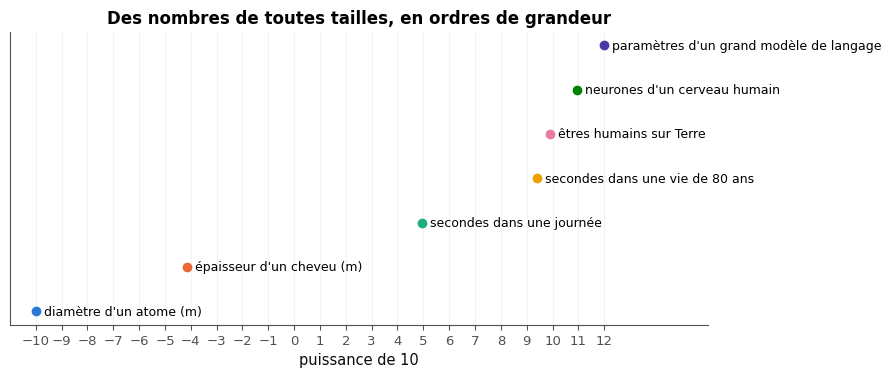

cheveu -> paramètres : 16 puissances de 10 environ


In [37]:
def plot_magnitudes(quantities):
    """Draw each quantity as a point at x = log10(value), with its label; title, axis label, ticks."""
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for i, (label, value) in enumerate(quantities.items()):
        x = math.log10(value)
        ax.plot(x, i, "o")
        ax.annotate(label, (x, i), xytext=(6, -3), textcoords="offset points", fontsize=9)
    ax.set_xticks(range(-10, 13))
    ax.set_yticks([])
    ax.set_xlim(-11, 16)
    ax.set_xlabel("puissance de 10")
    ax.set_title("Des nombres de toutes tailles, en ordres de grandeur")
    ax.grid(True, axis="x", alpha=0.4)
    plt.show()


plot_magnitudes(quantities)
print("cheveu -> paramètres :", round(math.log10(1e12) - math.log10(7e-5)), "puissances de 10 environ")

## Partie C · Pourcentages et moyennes

Fiche §7 et §8. Tes deux dernières fonctions de `arith.py`, une expérience sur les hausses répétées, et une docstring.

### Ex R1.24 — Évolutions successives et moyenne pondérée · `successive_changes`, `weighted_mean` 🔨 ★ ⏱️ 30 min
**Objectif :** programmer le taux global d'évolutions successives et la moyenne pondérée, avec leurs cas d'erreur.  
**Prérequis :** fiche §7 et §8 ; workbookIA 0A §100.6.2 (`raise`) · **mymath :** `arith.py` · **Parcours :** C, E

Dans `mon_travail/mymath/arith.py` :
- a) `successive_changes(rates)` : les taux sont écrits en décimal (`0.10` pour +10 %). Multiplie les coefficients $1 + t$, puis repasse du coefficient global au taux global. Une liste vide donne `0.0` ; un taux inférieur à −1 (−100 %) lève une `ValueError`.
- b) `weighted_mean(values, weights)` : la somme des valeur × poids, divisée par la somme des poids. Trois cas lèvent une `ValueError` : des longueurs différentes, un poids négatif, des poids de somme nulle.

La vérification calcule `successive_changes([0.3, -0.2, 0.05])` et `weighted_mean([11, 17, 8], [2, 3, 5])`.

In [38]:
mymath = wbm.load_mymath("ref")
print("successive_changes([0.3, -0.2, 0.05]) =", mymath.arith.successive_changes([0.3, -0.2, 0.05]))
print("weighted_mean([11, 17, 8], [2, 3, 5]) =", mymath.arith.weighted_mean([11, 17, 8], [2, 3, 5]))

successive_changes([0.3, -0.2, 0.05]) = 0.09200000000000008
weighted_mean([11, 17, 8], [2, 3, 5]) = 11.3


In [39]:
wbm.record("R1.24a", 1.3 * 0.8 * 1.05 - 1, decimals=4,
           mistakes={"les coefficients se multiplient, les taux ne s'additionnent pas": 0.15,
                     "renvoie le taux global (le coefficient moins 1), pas le coefficient": 1.3 * 0.8 * 1.05})
wbm.record("R1.24b", (11 * 2 + 17 * 3 + 8 * 5) / (2 + 3 + 5), decimals=4,
           mistakes={"divise par la somme des poids, pas par le nombre de valeurs": (11 * 2 + 17 * 3 + 8 * 5) / 3,
                     "c'est une moyenne pondérée, pas une moyenne simple": (11 + 17 + 8) / 3})

WBM_ANSWER {"coarse_any": {"1": ["c8bc8bd1f6cf48f8ffeeba7777d432989fdacf7d984f104ed79e4306cbaf4fbb"], "2": ["bb5ace6b71740c5fff55b3dc8aa50cb4e188b4fb521e65f9737316c732cfc2f2"]}, "decimals": 4, "hash": "bcfabdfb9d0838cae4ce3eecc12e58312dc2b7314b50e6fd9c543d574c1cb2ae", "hash_coarse": "14eefafd0297a617a4e3c0207795a924abc91dcfb21105bd70ebd0b8ca66f02b", "id": "R1.24a", "kind": "float", "magnitude": -2, "mistakes": {"5449e2bdfce4463355c34eefe281a5a4fe6f5faad634179d8468d1ca2eb6bb0c": "les coefficients se multiplient, les taux ne s'additionnent pas", "a80bcf262fdb6ed96727254a629d249ef12b8dfc754f0325c1877414652cd45e": "renvoie le taux global (le coefficient moins 1), pas le coefficient"}, "sign": 1}
📝 Ex R1.24a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["5aac699c3915c6a8186215cee6cde120523afbe5e680a35de5db7e8690a1d3b1"]}, "coarser": {"1": ["f26ccf7e4f26c306e94e8926eaa31285bfa5603cafb7c058a8aeab6e59b6fda4"], "2": ["cedd8c9ce5e30d75bdd80955e2f074b47166fba48d8d30

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [40]:
run_pytest_group("tests/test_r1_arith.py", "test_successive_changes_ or test_weighted_mean_ or test_arith_uses", impl="ref")

pytest: 17 réussi(s), 37 non sélectionné(s) en 0,02 s


### Ex R1.27 — Après n hausses de 10 % : tracer et comparer à une hausse de 10n % 🔬 ★★ ⏱️ 20 min
**Objectif :** voir qu'une évolution répétée suit une puissance, qui finit par écraser une croissance de taux additionnés.  
**Prérequis :** fiche §7, « Évolutions successives » · **Parcours :** C

Un prix de 1 € augmente de 10 % chaque année. Après $n$ années, il vaut $1{,}1^n$ euros. Un camarade pense qu'il vaut $1 + 0{,}1n$ (« 10 % par an, donc $10n$ % en $n$ ans »).

- Trace les deux courbes, $1{,}1^n$ et $1 + 0{,}1n$, pour $n$ entier de 0 à 30 (points reliés, une légende, un titre, des axes nommés).
- a) Au bout de combien d'années le prix a-t-il **doublé** pour la première fois ($1{,}1^n \ge 2$) ? Un entier.
- b) Que vaut $1{,}1^{30}$, arrondi au centième ?

Pour a), une boucle `while` qui multiplie par 1,1 tant que le prix est inférieur à 2 suffit.

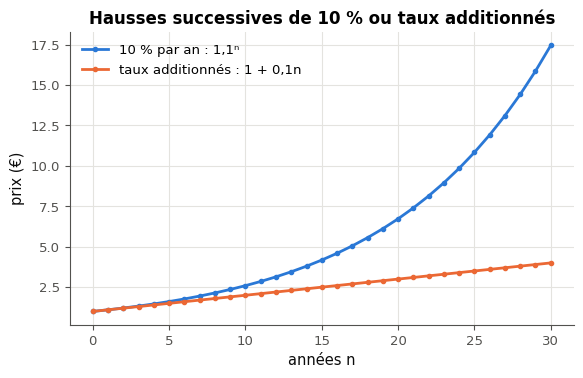

doublement après 8 ans ; 1,1^30 = 17.45 ; 1 + 0,1 × 30 = 4.0


In [41]:
def plot_growth(n_max=30):
    """Plot 1.1**n and 1 + 0.1*n for n = 0, 1, ..., n_max (legend, title, axis labels)."""
    n = np.arange(n_max + 1)
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.plot(n, 1.1**n, "o-", markersize=3, label="10 % par an : 1,1ⁿ")
    ax.plot(n, 1 + 0.1 * n, "o-", markersize=3, label="taux additionnés : 1 + 0,1n")
    ax.set_xlabel("années n")
    ax.set_ylabel("prix (€)")
    ax.set_title("Hausses successives de 10 % ou taux additionnés")
    ax.grid(True)
    ax.legend()
    plt.show()


plot_growth()
price, years = 1.0, 0
while price < 2:
    price *= 1.1
    years += 1
answer_R1_27a, answer_R1_27b = years, round(1.1**30, 2)
print("doublement après", years, "ans ; 1,1^30 =", answer_R1_27b, "; 1 + 0,1 × 30 =", 1 + 0.1 * 30)

In [42]:
wbm.record("R1.27a", 8,
           mistakes={"vérifie ta condition d'arrêt : le prix doit avoir atteint 2 €, pas seulement s'en approcher": 7,
                     "les taux ne s'additionnent pas : les hausses se multiplient, le doublement vient plus tôt": 10})
wbm.record("R1.27b", round(1.1**30, 2), decimals=2,
           mistakes={"c'est une puissance, pas une somme de taux : multiplie trente fois par 1,1": 4.0})

WBM_ANSWER {"hash": "4e97520c0cfd4d7e7da691f245d7360d19e226853b65b6d87da8ab989e59d7f3", "id": "R1.27a", "kind": "int", "magnitude": 0, "mistakes": {"4c1459da9b34e96f31c52383af269692154f2b84f78fb13e3e7755935c706129": "vérifie ta condition d'arrêt : le prix doit avoir atteint 2 €, pas seulement s'en approcher", "6ec12cfb3a75078a04465f39c12939440571c999d26b0603b33090c40fac79eb": "les taux ne s'additionnent pas : les hausses se multiplient, le doublement vient plus tôt"}, "sign": 1}
📝 Ex R1.27a : réponse enregistrée (int).
WBM_ANSWER {"alt_coarse": ["5ea57821b4d8509efb2005e397d49a24e1a8c2318e90f5477abb1ba716566c52"], "coarse_any": {"0": ["7cb3bf32f7ffc3c6ad2cf479b629f690c05b9489068a2fae38e76421d8ac11f6"]}, "decimals": 2, "hash": "73c3ad653e6430416414088ae84ddc9fae8dbcb8a22588df1ba34a3472bc43d4", "hash_coarse": "8a6804416fa9ac17e9f64456b497bc0db543a576d7b3d6344a5246e9e4957b94", "id": "R1.27b", "kind": "float", "magnitude": 1, "mistakes": {"16319c08991a180c5420b95af0d3b0b7c27a1db9c998d9c6156

💡 Doubler en 8 ans à 10 % par an : c'est la « règle de 72 » des financiers (72 ÷ 10 ≈ 7,2 ans, une approximation). Les deux courbes sont proches au début, puis la puissance s'envole : à 30 ans, 17,45 € contre 4 €. Tu retrouveras cette croissance au chapitre R5 (suites géométriques) et R6 (exponentielle).

### Ex R1.31 — Écrire la docstring d'une fonction (format NumPy) 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une docstring complète, au format NumPy, avec des exemples exécutables.  
**Prérequis :** fiche §8 (moyenne harmonique) ; workbookIA 0A §100.5.5 (docstrings) · **Parcours :** C

La fonction `harmonic_mean` (fiche §8, la moyenne harmonique) marche, mais personne ne sait comment s'en servir : elle n'a pas de docstring. Écris-la, **en anglais** comme tout le code du dépôt, au format NumPy que tu as vu dans 0A (§100.5.5) et dans les fichiers de `mymath` :
- une première ligne qui dit ce que fait la fonction ;
- `Parameters`, `Returns` et `Raises` (les deux cas d'erreur du code) ;
- `Examples` : au moins deux exemples `>>>` avec leur résultat, que tu calcules à la main (par exemple la moyenne harmonique de 90 et de 60 de la fiche). Écris le résultat exactement comme Python l'affiche : un flottant, `72.0`. Choisis des exemples dont le calcul en flottants tombe juste (évite les tiers et les septièmes).

La vérification regarde que les quatre sections sont là, puis **exécute tes exemples** (`doctest`) : un exemple dont le résultat diffère de ce que tu as écrit est signalé. Compare ensuite ta docstring à celle de `05_solutions.ipynb` : plusieurs rédactions sont justes.

In [43]:
def harmonic_mean(values):
    """Return the harmonic mean of positive numbers: the inverse of the mean of their inverses.

    Parameters
    ----------
    values : sequence of float
        Strictly positive numbers (a speed, a rate...).

    Returns
    -------
    float
        ``n / (1/x1 + ... + 1/xn)``, never larger than the arithmetic mean.

    Raises
    ------
    ValueError
        If ``values`` is empty, or if a value is zero or negative.

    Examples
    --------
    >>> harmonic_mean([90, 60])
    72.0
    >>> harmonic_mean([3, 6])
    4.0
    """
    values = list(values)
    if len(values) == 0:
        raise ValueError("cannot compute the harmonic mean of an empty sequence")
    if any(v <= 0 for v in values):
        raise ValueError("the harmonic mean needs positive values")
    return len(values) / sum(1 / v for v in values)


with wbm.attempt("R1.31"):
    doc = harmonic_mean.__doc__ or ""
    if doc.strip().startswith("TODO"):
        raise NotImplementedError("écris la docstring")
    missing = [section for section in ("Parameters", "Returns", "Raises", "Examples") if section not in doc]
    if missing:
        print("❌ Ex R1.31 : il manque ces sections dans la docstring :", ", ".join(missing))
    else:
        runner = doctest.DocTestRunner()
        for test in doctest.DocTestFinder().find(harmonic_mean, "harmonic_mean", globs={"harmonic_mean": harmonic_mean}):
            runner.run(test)
        failed, attempted = runner.summarize(verbose=False)
        if attempted < 2:
            print(f"❌ Ex R1.31 : {attempted} exemple(s) >>> dans la docstring ; il en faut au moins deux.")
        elif failed:
            print(f"❌ Ex R1.31 : {failed} exemple(s) sur {attempted} ne donnent pas le résultat écrit (détail au-dessus).")
        else:
            print(f"✅ Ex R1.31 : quatre sections, et {attempted} exemples qui donnent bien le résultat écrit.")

✅ Ex R1.31 : quatre sections, et 2 exemples qui donnent bien le résultat écrit.


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu sans erreur avec des priorités, des négatifs, des fractions et des puissances, et repères-tu les « règles » qui n'existent pas ?
2. Sais-tu écrire un nombre en notation scientifique, l'arrondir et donner son ordre de grandeur ?
3. Sais-tu enchaîner des évolutions en pourcentage et calculer une moyenne pondérée, à la main et avec `mymath` ?

**La suite** : R2, *Calcul littéral et équations*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.